# Resume RAG & Hybrid Job Matching Engine

This notebook demonstrates the complete end-to-end **Resume RAG + Job Matching Engine**.

### Pipeline Architecture:
1. **Multi-Format Document Ingestion**: Parsing resumes from PDF, DOCX, and TXT formats with OCR fallback.
2. **Intelligent Section-Aware Chunking**: Structuring resume text into section boundaries (`EXPERIENCE`, `EDUCATION`, `SKILLS`, `PROJECTS`, `CERTIFICATIONS`).
3. **Structured Metadata Extraction**: Extracting candidate names, recognized technical skills, years of experience, and highest education.
4. **Vector DB Indexing**: Generating embeddings with `sentence-transformers/all-MiniLM-L6-v2` and persisting in ChromaDB.
5. **Hybrid Matching Engine**: Combining BM25 keyword matching + vector similarity, candidate hard-filtering, 0-100 weighted scoring, and match reasoning.
6. **Performance Benchmarking**: Measuring Precision@K, Recall@K, and end-to-end query latency.

In [1]:
import os
import sys
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Custom Module Imports
from src.document_processor import DocumentProcessor
from src.text_processor import TextProcessor
from src.metadata_extractor import MetadataExtractor
from src.embeddings import EmbeddingGenerator
from src.vector_store import ResumeVectorStore
from src.resume_rag import ResumeRAGPipeline
from src.job_matcher import JobMatcher

sns.set_theme(style="whitegrid")
print("[OK] Core pipeline modules imported successfully!")

[OK] Core pipeline modules imported successfully!


## 1. Document Parsing & Text Extraction
Testing text extraction on a sample PDF resume.

In [2]:
doc_processor = DocumentProcessor()
sample_pdf = str(PROJECT_ROOT / "data/selected_resumes/Python Developer/103.pdf")
raw_text = doc_processor.extract_text(sample_pdf)

print(f"File: {sample_pdf}")
print(f"Extracted Character Count: {len(raw_text)}")
print("\n--- Extracted Text Sample (First 350 chars) ---")
print(raw_text[:350])

File: C:\Users\Siddhant Darekar\Downloads\Airtribe Projects\AI\resume-rag-job-matcher\data\selected_resumes\Python Developer\103.pdf
Extracted Character Count: 6792

--- Extracted Text Sample (First 350 chars) ---
JESSICA CLAIRE

100 Montgomery St. 10th Floor
(555) 432-1000 - resumesample@example.com

PROFESSIONAL SUMMARY

Over 8 years of IT experience in Data warehousing and Business intelligence with an emphasis on Project Planning & Management, Business
Requirements Analysis, Application Design, Development, testing, implementation, and maintenance of cli


## 2. Section-Aware Chunking (Before vs. After)
Demonstrating naive fixed-size character chunking vs. our intelligent section-header boundary chunking.

In [3]:
text_processor = TextProcessor()
cleaned_text = text_processor.clean_text(raw_text)

# Naive character/word splitting
words = cleaned_text.split()
naive_chunks = [" ".join(words[i:i+100]) for i in range(0, len(words), 80)]

# Section-aware chunking
section_chunks = text_processor.chunk_text(cleaned_text, max_words=200)

print("=== NAIVE FIXED-SIZE SLIDING WINDOW CHUNKING (Sample Chunk 1) ===")
print(naive_chunks[0][:220] + "...\n")

print("=== INTELLIGENT SECTION-AWARE CHUNKING (Sample Chunks) ===")
for idx, chunk in enumerate(section_chunks[:3]):
    print(f"--- Chunk {idx+1} [Section: {chunk['section']}] ---")
    print(chunk['text'][:220] + "...\n")

=== NAIVE FIXED-SIZE SLIDING WINDOW CHUNKING (Sample Chunk 1) ===
JESSICA CLAIRE 100 Montgomery St. 10th Floor (555) 432-1000 - resumesample@example.com PROFESSIONAL SUMMARY Over 8 years of IT experience in Data warehousing and Business intelligence with an emphasis on Project Planning...

=== INTELLIGENT SECTION-AWARE CHUNKING (Sample Chunks) ===
--- Chunk 1 [Section: GENERAL] ---
[Section: GENERAL]
JESSICA CLAIRE

100 Montgomery St. 10th Floor
(555) 432-1000 - resumesample@example.com...

--- Chunk 2 [Section: SUMMARY] ---
[Section: SUMMARY]
Over 8 years of IT experience in Data warehousing and Business intelligence with an emphasis on Project Planning & Management, Business
Requirements Analysis, Application Design, Development, testing, ...

--- Chunk 3 [Section: EXPERIENCE] ---
[Section: EXPERIENCE]
01/2020 to Current Data Engineer (Snowflake Developer) Brown & Brown, Inc. — Walnut Creek, CA. * Bulk loading from the external stage (AWS $3), intemal stage to snowflake cloud using t

## 3. Structured Metadata Extraction
Extracting candidate name, technical skills taxonomy, total years of experience, and highest education.

In [4]:
extractor = MetadataExtractor()
metadata = extractor.extract_metadata(cleaned_text, filename=Path(sample_pdf).name)

print("Extracted Structured Metadata:")
print(json.dumps(metadata, indent=2))

Extracted Structured Metadata:
{
  "candidate_name": "Jessica Claire",
  "skills": [
    "AWS",
    "Business Analysis",
    "ETL",
    "Java",
    "Mysql",
    "Oracle",
    "Pandas",
    "Python",
    "SQL",
    "Scrum",
    "Snowflake"
  ],
  "total_years_experience": 6.0,
  "highest_education": "Bachelor's"
}


## 4. Vector Store & RAG Ingestion Pipeline
Ingesting all 50 selected resumes into persistent ChromaDB storage.

In [5]:
pipeline = ResumeRAGPipeline(db_path=str(PROJECT_ROOT / "chroma_db"))
t0 = time.time()
processed_resumes = pipeline.ingest_directory(resumes_dir=str(PROJECT_ROOT / "data/selected_resumes"), reset_db=True)
t_ingest = time.time() - t0

print(f"\nIngested {len(processed_resumes)} resumes into ChromaDB in {t_ingest:.2f} seconds.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Found 50 resume files to process.
  [OK] Processed: Image_14.pdf [Business Analyst] (4 chunks)
  [OK] Processed: Image_15.pdf [Business Analyst] (2 chunks)
  [OK] Processed: Image_42.pdf [Business Analyst] (3 chunks)
  [OK] Processed: Image_46.pdf [Business Analyst] (5 chunks)
  [OK] Processed: Image_94.pdf [Business Analyst] (3 chunks)
  [OK] Processed: 121.pdf [Data Science] (9 chunks)
  [OK] Processed: 13.pdf [Data Science] (8 chunks)
  [OK] Processed: 75.pdf [Data Science] (9 chunks)
  [OK] Processed: 89.pdf [Data Science] (8 chunks)
  [OK] Processed: 9.pdf [Data Science] (7 chunks)
  [OK] Processed: 1.pdf [DevOps Engineer] (7 chunks)
  [OK] Processed: 134.pdf [DevOps Engineer] (7 chunks)
  [OK] Processed: 33.pdf [DevOps Engineer] (6 chunks)
  [OK] Processed: 48.pdf [DevOps Engineer] (7 chunks)
  [OK] Processed: 67.pdf [DevOps Engineer] (9 chunks)
  [OK] Processed: Image_13.pdf [Java Developer] (4 chunks)
  [OK] Processed: Image_14.pdf [Java Developer] (3 chunks)
  [OK] Processed: 

## 5. Job Matching Engine Execution
Executing hybrid matching for a sample Job Description and outputting exact target JSON structure.

In [6]:
matcher = JobMatcher(vector_store=pipeline.vector_store)

# Load sample JD
jd_file = str(PROJECT_ROOT / "data/job_descriptions/jd_1_python_developer.json")
with open(jd_file, "r") as f:
    sample_jd = json.load(f)

print(f"Job Role: {sample_jd['title']}")
print(f"Must Have Skills: {sample_jd['must_have_skills']}")
print(f"Required Experience: {sample_jd['required_experience_years']} years\n")

match_result = matcher.match(sample_jd, top_k=5)
print("=== TARGET OUTPUT JSON STRUCTURE ===")
print(json.dumps(match_result, indent=2))

Job Role: Senior Python Developer
Must Have Skills: ['Python', 'Django', 'FastAPI', 'PostgreSQL', 'REST APIs']
Required Experience: 4 years

=== TARGET OUTPUT JSON STRUCTURE ===
{
  "job_description": "We are seeking a Senior Python Developer with 4+ years of hands-on experience building scalable web APIs and backend systems using Python, Django, and FastAPI. The ideal candidate will have strong SQL skills with PostgreSQL, experience designing RESTful APIs, and familiarity with containerization using Docker. Responsibilities include designing database models, optimizing API endpoints, writing unit tests, and collaborating with frontend teams.",
  "top_matches": [
    {
      "candidate_name": "Jessica Claire",
      "resume_path": "C:\\Users\\Siddhant Darekar\\Downloads\\Airtribe Projects\\AI\\resume-rag-job-matcher\\data\\selected_resumes\\Python Developer\\34.pdf",
      "match_score": 70,
      "matched_skills": [
        "Django",
        "Postgresql",
        "Python"
      ],
   

## 6. Performance Evaluation & Benchmarking
Evaluating Retrieval Accuracy (**Precision@K** and **Recall@K**) and measuring **Latency** across all 5 test Job Descriptions.

In [7]:
jd_dir = PROJECT_ROOT / "data/job_descriptions"
jd_files = sorted(list(jd_dir.glob("*.json")))

precision_k = {5: [], 10: []}
recall_k = {5: [], 10: []}
latency_records = []

for jd_path in jd_files:
    with open(jd_path, "r") as f:
        jd_data = json.load(f)
    
    target_category = jd_data.get("category", "")
    
    # Measure Latency for K=5 and K=10
    t_start = time.time()
    res_5 = matcher.match(jd_data, top_k=5)
    t_q5 = (time.time() - t_start) * 1000
    
    t_start = time.time()
    res_10 = matcher.match(jd_data, top_k=10)
    t_q10 = (time.time() - t_start) * 1000
    
    latency_records.append({
        "Job Title": jd_data["title"],
        "Query Latency @ K=5 (ms)": round(t_q5, 2),
        "Query Latency @ K=10 (ms)": round(t_q10, 2)
    })
    
    # Calculate Relevant Candidates (Ground truth: 5 candidates exist in target category)
    total_relevant_in_db = 5.0
    
    # K=5
    matches_5 = res_5["top_matches"]
    rel_5 = sum(1 for m in matches_5 if target_category.lower() in m["resume_path"].lower() or target_category.lower() in m["candidate_name"].lower())
    precision_k[5].append(rel_5 / 5.0)
    recall_k[5].append(rel_5 / total_relevant_in_db)
    
    # K=10
    matches_10 = res_10["top_matches"]
    rel_10 = sum(1 for m in matches_10 if target_category.lower() in m["resume_path"].lower() or target_category.lower() in m["candidate_name"].lower())
    precision_k[10].append(rel_10 / 10.0)
    recall_k[10].append(rel_10 / total_relevant_in_db)

print("=== RETRIEVAL ACCURACY RESULTS ===")
print(f"Mean Precision@5 : {np.mean(precision_k[5]):.2%}")
print(f"Mean Recall@5    : {np.mean(recall_k[5]):.2%}")
print(f"Mean Precision@10: {np.mean(precision_k[10]):.2%}")
print(f"Mean Recall@10   : {np.mean(recall_k[10]):.2%}")

df_latency = pd.DataFrame(latency_records)
print("\n=== LATENCY BENCHMARK SUMMARY (ms) ===")
print(df_latency.to_string(index=False))

=== RETRIEVAL ACCURACY RESULTS ===
Mean Precision@5 : 56.00%
Mean Recall@5    : 56.00%
Mean Precision@10: 28.00%
Mean Recall@10   : 56.00%

=== LATENCY BENCHMARK SUMMARY (ms) ===
                  Job Title  Query Latency @ K=5 (ms)  Query Latency @ K=10 (ms)
    Senior Python Developer                    178.99                     124.58
        Lead Data Scientist                    119.64                     124.49
Java Microservices Engineer                    126.14                     116.19
     Senior DevOps Engineer                    116.84                     123.93
   Frontend React Developer                    119.70                     119.18


C:\Users\Siddhant Darekar\AppData\Local\Temp\ipykernel_36852\4043770727.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=metrics_df, x='Metric', y='Score (%)', palette='crest', ax=axes[0])
C:\Users\Siddhant Darekar\AppData\Local\Temp\ipykernel_36852\4043770727.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_latency, x='Job Title', y='Query Latency @ K=10 (ms)', palette='viridis', ax=axes[1])


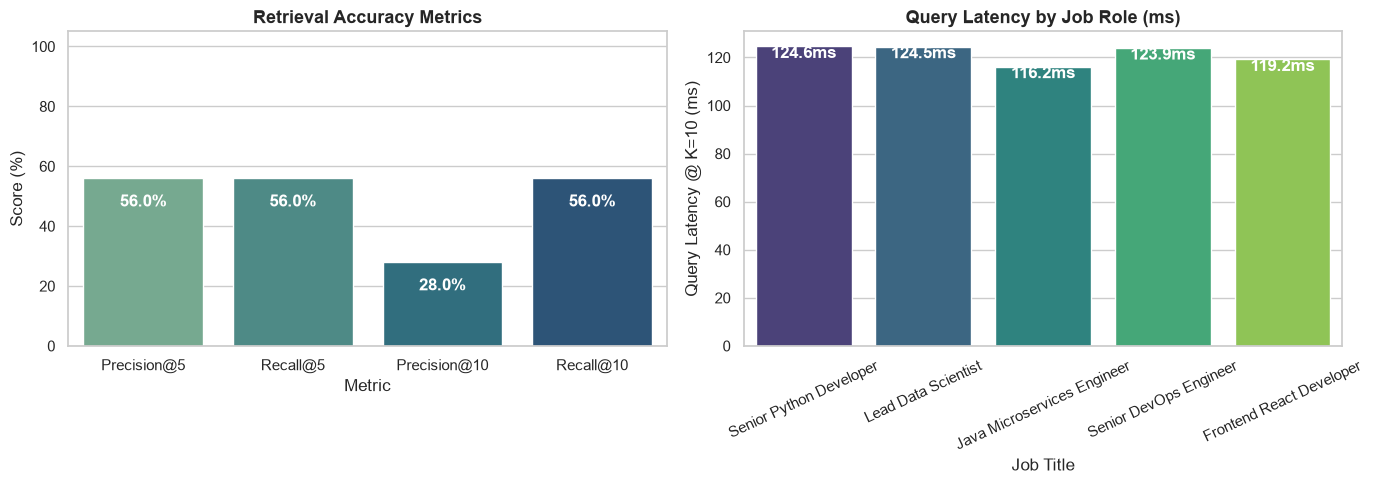

In [8]:
# Visualize Performance Metrics and Latency Graphs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Precision@K & Recall@K
metrics_df = pd.DataFrame({
    'Metric': ['Precision@5', 'Recall@5', 'Precision@10', 'Recall@10'],
    'Score (%)': [np.mean(precision_k[5])*100, np.mean(recall_k[5])*100, np.mean(precision_k[10])*100, np.mean(recall_k[10])*100]
})

sns.barplot(data=metrics_df, x='Metric', y='Score (%)', palette='crest', ax=axes[0])
axes[0].set_ylim(0, 105)
axes[0].set_title('Retrieval Accuracy Metrics', fontsize=13, fontweight='bold')
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() - 8),
                     ha='center', va='center', color='white', fontweight='bold')

# Subplot 2: Latency by Job Description
sns.barplot(data=df_latency, x='Job Title', y='Query Latency @ K=10 (ms)', palette='viridis', ax=axes[1])
axes[1].set_title('Query Latency by Job Role (ms)', fontsize=13, fontweight='bold')
axes[1].tick_params(axis='x', rotation=25)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}ms", (p.get_x() + p.get_width() / 2., p.get_height() - 3),
                     ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()